# A score-based diffusion model for Fashion-MNIST


This notebook implements the score matching training algorithm from lecture and uses the learned score to generate new Fashion-MNIST images by running the SDE backward in time.

Note: This notebook was completely written by Claude Code, prompted by me (JL) to follow the presentation of the algorithm from my lecture.

**Running on Colab.** Choose *Runtime → Change runtime type* and pick a **GPU** (T4 is fine) or a **TPU**. The first code cell finds the accelerator and, on a TPU runtime, installs PyTorch/XLA. With the default settings, training takes roughly 15–20 minutes on a T4 GPU.

### The model

The forward process is the SDE from lecture with a linear drift,
$$
dX_t = b(X_t, t)\,dt + \sqrt{\nu}\, dW_t, \qquad b(x,t) = -k x,
$$
started at a data point $X_0 = z$. This is an Ornstein–Uhlenbeck process, so the conditional distribution is Gaussian:
$$
X_t \mid X_0 = z \;\sim\; N\big(\alpha_t z,\; \beta_t^2 I\big), \qquad
\alpha_t = e^{-k t}, \qquad \beta_t^2 = \frac{\nu}{2k}\big(1 - e^{-2k t}\big).
$$
As $t \to \infty$ this tends to the stationary distribution $N(0, \tfrac{\nu}{2k} I)$, which is $N(0, I)$ for our choice $k = 1/2$, $\nu = 1$.

The backward drift is $b_*(x,t) = b(x,t) - \nu\, \nabla \log \rho(x,t)$, so to sample we only need the score $\nabla\log\rho(x,t)$, which we learn with a network $s_\theta(x,t)$.

### Changes from the algorithm on the slide

The algorithm on the slide is followed exactly, with four practical changes:

1. **Times are drawn from $[t_{\min}, T]$, not $[0, T]$.** As $t \to 0$ we have $\beta_t \to 0$, and the target $-\epsilon/\beta_t$ blows up. We use $t_{\min} = 10^{-3}$.
2. **The network predicts the noise.** The network $\hat\epsilon_\theta(x,t)$ outputs a guess of $\epsilon$, and the score is $s_\theta(x,t) = -\hat\epsilon_\theta(x,t)/\beta_t$. The loss $\|\hat\epsilon_\theta - \epsilon\|^2 = \|\beta_t\, s_\theta + \epsilon\|^2$ is the conditional score matching loss weighted by $\beta_t^2$. It has the same minimizer, but every time $t$ now contributes on the same scale, which makes training much more stable.
3. **The loss is averaged over pixels as well as the batch.** This rescales the loss by the constant $1/d$, with $d = 784$.
4. **The weights used for sampling are an exponential moving average (EMA) of the training weights.** This is standard practice and gives noticeably cleaner samples.

For sampling, the reverse-time Euler–Maruyama steps use a time grid that is finer near $t = 0$; see the sampling section.

In [1]:
# Setup: detect the accelerator and, on a Colab TPU runtime, install PyTorch/XLA.
import glob, importlib.metadata, importlib.util, os, subprocess, sys

def tpu_present():
    return bool(glob.glob("/dev/accel*") or glob.glob("/dev/vfio/[0-9]*")
                or os.environ.get("COLAB_TPU_ADDR") or os.environ.get("TPU_ACCELERATOR_TYPE"))

if tpu_present() and importlib.util.find_spec("torch_xla") is None:
    try:
        torch_version = importlib.metadata.version("torch").split("+")[0]
        major_minor = ".".join(torch_version.split(".")[:2])
        packages = [f"torch=={torch_version}", f"torch_xla[tpu]=={major_minor}.*"]
    except importlib.metadata.PackageNotFoundError:
        packages = ["torch", "torch_xla[tpu]"]
    print("TPU detected; installing", " ".join(packages))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages,
                    "-f", "https://storage.googleapis.com/libtpu-releases/index.html"], check=True)

In [2]:
import copy, math, time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.utils import make_grid

if torch.cuda.is_available():
    BACKEND, device = "cuda", torch.device("cuda")
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
elif importlib.util.find_spec("torch_xla") is not None and tpu_present():
    import torch_xla
    import torch_xla.core.xla_model as xm
    BACKEND = "xla"
    device = torch_xla.device() if hasattr(torch_xla, "device") else xm.xla_device()
elif torch.backends.mps.is_available():
    BACKEND, device = "mps", torch.device("mps")
else:
    BACKEND, device = "cpu", torch.device("cpu")


def sync():
    # On a TPU, PyTorch/XLA records operations lazily; this runs the recorded graph.
    # On other devices it does nothing.
    if BACKEND == "xla":
        torch_xla.sync() if hasattr(torch_xla, "sync") else xm.mark_step()


print(f"Using {BACKEND} ({device})")
if BACKEND == "cpu":
    print("No accelerator found: training will be very slow. "
          "In Colab, choose Runtime -> Change runtime type -> GPU or TPU.")

Using cuda (cuda)


## Settings

In [ ]:
# Forward SDE: dX_t = -K * X_t dt + sqrt(NU) dW_t on [T_MIN, T]
K = 0.5
NU = 1.0
T = 6.0          # alpha_T = e^{-3} ~ 0.05, so X_T is close to N(0, I)
T_MIN = 1e-3

# Training
BATCH_SIZE = 128
EPOCHS = 20
LR = 2e-4
EMA_DECAY = 0.999
SEED = 0

# Sampling
N_SAMPLE_STEPS = 1000

DATA_DIR = "./data"
torch.manual_seed(SEED)
np.random.seed(SEED)

## The forward process

`alpha_beta(t)` gives the mean factor $\alpha_t$ and standard deviation $\beta_t$ of $X_t \mid X_0 = z$, and `drift` is $b(x,t) = -k x$.

In [ ]:
def alpha_beta(t):
    alpha = torch.exp(-K * t)
    beta = torch.sqrt(NU / (2 * K) * -torch.expm1(-2 * K * t))
    return alpha, beta


def drift(x, t):
    return -K * x


def bcast(v):
    # Reshape a per-example vector of shape (B,) to (B, 1, 1, 1) so it broadcasts over images.
    return v[:, None, None, None]

## Data

The images are scaled to $[-1, 1]$. The whole training set (60,000 images) is small enough to hold in memory, so each mini-batch is a random set of indices $\mathcal B \subset \{1, \ldots, n\}$, exactly as in the algorithm.

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.9MB/s]


training images: (60000, 1, 28, 28)


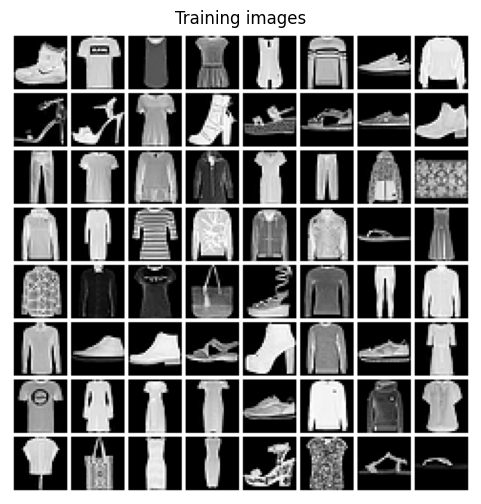

In [5]:
train_set = torchvision.datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
Z = train_set.data.float().div(127.5).sub(1.0).unsqueeze(1)   # (n, 1, 28, 28), values in [-1, 1]
if BACKEND == "cuda":
    Z = Z.pin_memory()
n = Z.shape[0]
print("training images:", tuple(Z.shape))


def show_grid(images, nrow=8, title=None, ax=None):
    grid = make_grid((images.float().cpu() + 1) / 2, nrow=nrow, padding=2, pad_value=1.0)
    ax = ax or plt.gca()
    ax.imshow(grid.permute(1, 2, 0).clamp(0, 1), cmap="gray")
    ax.axis("off")
    if title:
        ax.set_title(title)


plt.figure(figsize=(6, 6))
show_grid(Z[:64], title="Training images")
plt.show()

Running the forward process from a few training images. Each row is one image $z$, and the columns show draws of $X_t = \alpha_t z + \beta_t \epsilon$ at increasing times $t$.

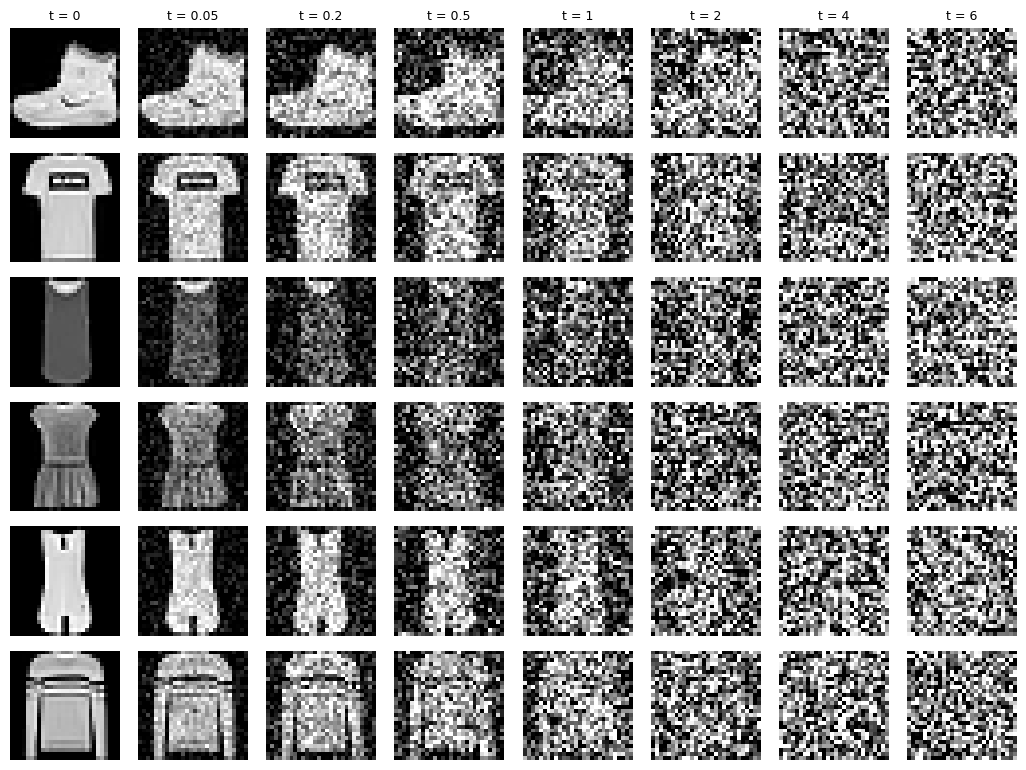

In [6]:
show_times = torch.tensor([0.0, 0.05, 0.2, 0.5, 1.0, 2.0, 4.0, T])
z = Z[:6]
alpha, beta = alpha_beta(show_times)
fig, axes = plt.subplots(len(z), len(show_times), figsize=(1.3 * len(show_times), 1.3 * len(z)))
for j, t in enumerate(show_times):
    x_t = alpha[j] * z + beta[j] * torch.randn_like(z)
    for i in range(len(z)):
        axes[i, j].imshow(x_t[i, 0], cmap="gray", vmin=-1, vmax=1)
        axes[i, j].axis("off")
    axes[0, j].set_title(f"t = {t:g}", fontsize=9)
plt.tight_layout()
plt.show()

## The score network

A small U-Net takes a noisy image $x$ and the time $t$ and predicts the noise $\hat\epsilon_\theta(x,t)$. The resolution goes $28 \to 14 \to 7$ and back, with skip connections between matching resolutions and self-attention at $7 \times 7$. The time enters through a sinusoidal embedding that is added inside each residual block.

The score is then $s_\theta(x,t) = -\hat\epsilon_\theta(x,t) / \beta_t$.

In [7]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim, out_dim):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, out_dim), nn.SiLU(), nn.Linear(out_dim, out_dim))

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
        args = (1000.0 * t / T)[:, None] * freqs[None, :]
        return self.mlp(torch.cat([torch.sin(args), torch.cos(args)], dim=1))


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.time = nn.Linear(t_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.heads = heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, 3 * channels, 1)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.norm(x)).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = (u.transpose(-1, -2) for u in qkv.unbind(1))   # each (B, heads, HW, C/heads)
        h = F.scaled_dot_product_attention(q, k, v)
        return x + self.proj(h.transpose(-1, -2).reshape(B, C, H, W))


class UNet(nn.Module):
    def __init__(self, ch=(64, 128, 256), t_dim=256):
        super().__init__()
        c1, c2, c3 = ch
        self.time = TimeEmbedding(c1, t_dim)
        self.inc = nn.Conv2d(1, c1, 3, padding=1)
        self.down1 = ResBlock(c1, c1, t_dim)                        # 28 x 28
        self.pool1 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)     # -> 14 x 14
        self.down2 = ResBlock(c1, c2, t_dim)
        self.pool2 = nn.Conv2d(c2, c2, 3, stride=2, padding=1)     # -> 7 x 7
        self.down3 = ResBlock(c2, c3, t_dim)
        self.mid1 = ResBlock(c3, c3, t_dim)
        self.attn = SelfAttention(c3)
        self.mid2 = ResBlock(c3, c3, t_dim)
        self.up3 = ResBlock(2 * c3, c3, t_dim)
        self.unpool2 = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                     nn.Conv2d(c3, c3, 3, padding=1))   # -> 14 x 14
        self.up2 = ResBlock(c3 + c2, c2, t_dim)
        self.unpool1 = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                                     nn.Conv2d(c2, c2, 3, padding=1))   # -> 28 x 28
        self.up1 = ResBlock(c2 + c1, c1, t_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, c1), nn.SiLU(), nn.Conv2d(c1, 1, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight)
        nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t):
        e = self.time(t)
        h1 = self.down1(self.inc(x), e)
        h2 = self.down2(self.pool1(h1), e)
        h3 = self.down3(self.pool2(h2), e)
        h = self.mid2(self.attn(self.mid1(h3, e)), e)
        h = self.up3(torch.cat([h, h3], dim=1), e)
        h = self.up2(torch.cat([self.unpool2(h), h2], dim=1), e)
        h = self.up1(torch.cat([self.unpool1(h), h1], dim=1), e)
        return self.out(h)


def score(net, x, t):
    # s_theta(x, t) = -eps_hat(x, t) / beta_t
    _, beta = alpha_beta(t)
    return -net(x, t) / bcast(beta)


model = UNet().to(device)
ema = copy.deepcopy(model).eval()
for p in ema.parameters():
    p.requires_grad_(False)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

parameters: 7.92M


## Training

This is the algorithm from the slide. For each random mini-batch $\mathcal B$, and for each $i \in \mathcal B$:

- sample $t_i \sim \text{Unif}[t_{\min}, T]$ and $\epsilon_i \sim N(0, I_d)$,
- set $x_i = \alpha_{t_i} z_i + \beta_{t_i}\, \epsilon_i$.

Then take a gradient step on
$$
\mathcal L_{\mathcal B}(\theta) = \frac{1}{|\mathcal B|\, d} \sum_{i \in \mathcal B} \big\| \hat\epsilon_\theta(x_i, t_i) - \epsilon_i \big\|^2
= \frac{1}{|\mathcal B|\, d} \sum_{i \in \mathcal B} \big\| \beta_{t_i} s_\theta(x_i, t_i) + \epsilon_i \big\|^2 .
$$
The per-example loop is vectorized: all $t_i$ and $\epsilon_i$ in a batch are drawn at once.

On a TPU, the first step takes a minute or two while XLA compiles the training step. Later steps are fast.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)


def train_step(z, ema_decay):
    B = z.shape[0]
    t = T_MIN + (T - T_MIN) * torch.rand(B, device=device)     # t_i ~ Unif[T_MIN, T]
    eps = torch.randn_like(z)                                    # eps_i ~ N(0, I_d)
    alpha, beta = alpha_beta(t)
    x = bcast(alpha) * z + bcast(beta) * eps                     # x_i = alpha_{t_i} z_i + beta_{t_i} eps_i
    loss = F.mse_loss(model(x, t), eps)                          # mean of ||beta s_theta + eps||^2 / d

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    with torch.no_grad():
        for p_ema, p in zip(ema.parameters(), model.parameters()):
            p_ema.lerp_(p, 1.0 - ema_decay)   # ema_decay is a tensor, so a TPU does not recompile
    return loss.detach()


steps_per_epoch = n // BATCH_SIZE        # drop the last partial batch so every batch has the same shape
LOG_EVERY = 100
loss_log = []
running = torch.zeros((), device=device)
step = 0
start = time.time()
for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(n)
    for k in range(steps_per_epoch):
        batch = perm[k * BATCH_SIZE:(k + 1) * BATCH_SIZE]        # a random mini-batch B
        z = Z[batch].to(device, non_blocking=True)
        # Warm up the EMA so early (random) weights are forgotten quickly.
        ema_decay = torch.tensor(min(EMA_DECAY, (1 + step) / (10 + step))).to(device)
        running = running + train_step(z, ema_decay)
        sync()
        step += 1
        if step % LOG_EVERY == 0:
            loss_log.append(running.item() / LOG_EVERY)
            running = torch.zeros((), device=device)
    print(f"epoch {epoch + 1:3d}/{EPOCHS}   loss {loss_log[-1]:.4f}   "
          f"elapsed {(time.time() - start) / 60:5.1f} min")

torch.save({k: v.cpu() for k, v in ema.state_dict().items()}, "fashion_mnist_score_ema.pt")

epoch   1/20   loss 0.0265   elapsed   1.2 min
epoch   2/20   loss 0.0221   elapsed   2.4 min
epoch   3/20   loss 0.0212   elapsed   3.7 min
epoch   4/20   loss 0.0205   elapsed   5.0 min
epoch   5/20   loss 0.0194   elapsed   6.2 min
epoch   6/20   loss 0.0197   elapsed   7.5 min
epoch   7/20   loss 0.0195   elapsed   8.7 min
epoch   8/20   loss 0.0192   elapsed  10.0 min
epoch   9/20   loss 0.0190   elapsed  11.3 min
epoch  10/20   loss 0.0185   elapsed  12.5 min
epoch  11/20   loss 0.0184   elapsed  13.8 min
epoch  12/20   loss 0.0193   elapsed  15.1 min
epoch  13/20   loss 0.0182   elapsed  16.3 min
epoch  14/20   loss 0.0181   elapsed  17.6 min
epoch  15/20   loss 0.0186   elapsed  18.9 min
epoch  16/20   loss 0.0184   elapsed  20.1 min
epoch  17/20   loss 0.0182   elapsed  21.4 min
epoch  18/20   loss 0.0179   elapsed  22.6 min
epoch  19/20   loss 0.0184   elapsed  23.9 min
epoch  20/20   loss 0.0177   elapsed  25.2 min


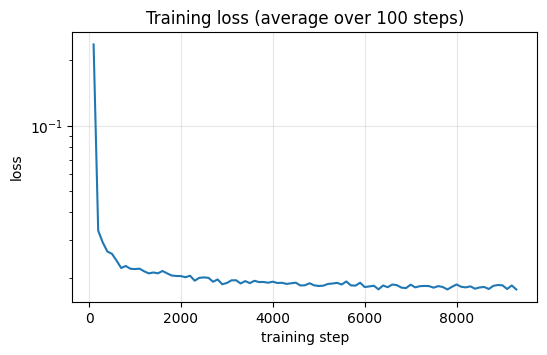

In [9]:
plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, len(loss_log) + 1) * LOG_EVERY, loss_log)
plt.xlabel("training step")
plt.ylabel("loss")
plt.yscale("log")
plt.title(f"Training loss (average over {LOG_EVERY} steps)")
plt.grid(alpha=0.3)
plt.show()

## Sampling: Euler–Maruyama in reverse time

Start from the stationary distribution $X_T \sim N(0, \tfrac{\nu}{2\theta} I)$ and step backward from $T$ to $t_{\min}$. With step size $h$, each step is
$$
X_{t-h} = X_t - h\, b_*(X_t, t) + \sqrt{\nu h}\; Z, \qquad
b_*(x,t) = b(x,t) - \nu\, s_\theta(x,t), \qquad Z \sim N(0, I).
$$
Most of the image structure appears at small $t$, so the time grid is uniform in $\log t$ rather than in $t$, which makes $h$ small near $t_{\min}$ and larger near $T$.

At the end we apply one denoising step using Tweedie's formula, $\hat z = \big(x + \beta_t^2\, s_\theta(x,t)\big)/\alpha_t$ at $t = t_{\min}$, which removes the last bit of noise.

sampling took 30.6 s


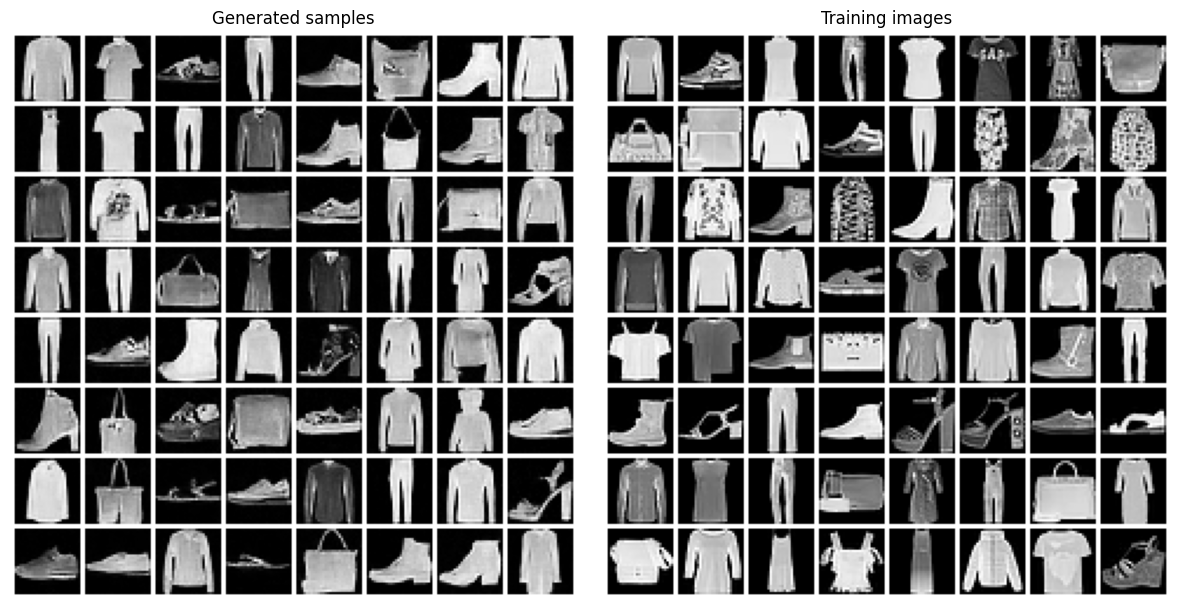

In [ ]:
@torch.no_grad()
def sample(net, n_samples=64, n_steps=N_SAMPLE_STEPS, seed=1,
           snapshot_times=(6.0, 2.0, 1.0, 0.5, 0.25, 0.1, 0.05, 0.02)):
    torch.manual_seed(seed)
    net.eval()
    # Time grid from T down to T_MIN, uniform in log t, so steps are small near t = 0.
    times = np.geomspace(T, T_MIN, n_steps + 1)
    snapshot_steps = {int(np.abs(times[:-1] - s).argmin()) for s in snapshot_times}
    snapshots = []

    x = math.sqrt(NU / (2 * K)) * torch.randn(n_samples, 1, 28, 28, device=device)
    for i in range(n_steps):
        if i in snapshot_steps:
            snapshots.append((times[i], x.cpu()))
        # t and h are created on the host and copied over, so on a TPU every step reuses
        # the same compiled graph.
        t = torch.full((n_samples,), float(times[i])).to(device)
        h = torch.full((n_samples,), float(times[i] - times[i + 1])).to(device)
        b_star = drift(x, t) - NU * score(net, x, t)
        x = x - bcast(h) * b_star + bcast(torch.sqrt(NU * h)) * torch.randn_like(x)
        sync()

    t = torch.full((n_samples,), float(times[-1])).to(device)
    alpha, beta = alpha_beta(t)
    z_hat = (x + bcast(beta) ** 2 * score(net, x, t)) / bcast(alpha)   # Tweedie denoising
    snapshots.append((times[-1], z_hat.cpu()))
    return z_hat.clamp(-1, 1).cpu(), snapshots


start = time.time()
samples, snapshots = sample(ema, n_samples=64)
print(f"sampling took {time.time() - start:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
show_grid(samples, title="Generated samples", ax=axes[0])
show_grid(Z[torch.randperm(n)[:64]], title="Training images", ax=axes[1])
plt.tight_layout()
plt.show()

The reverse-time trajectories for a few samples, running from pure noise at $t = T$ (left) to the final denoised image (right).

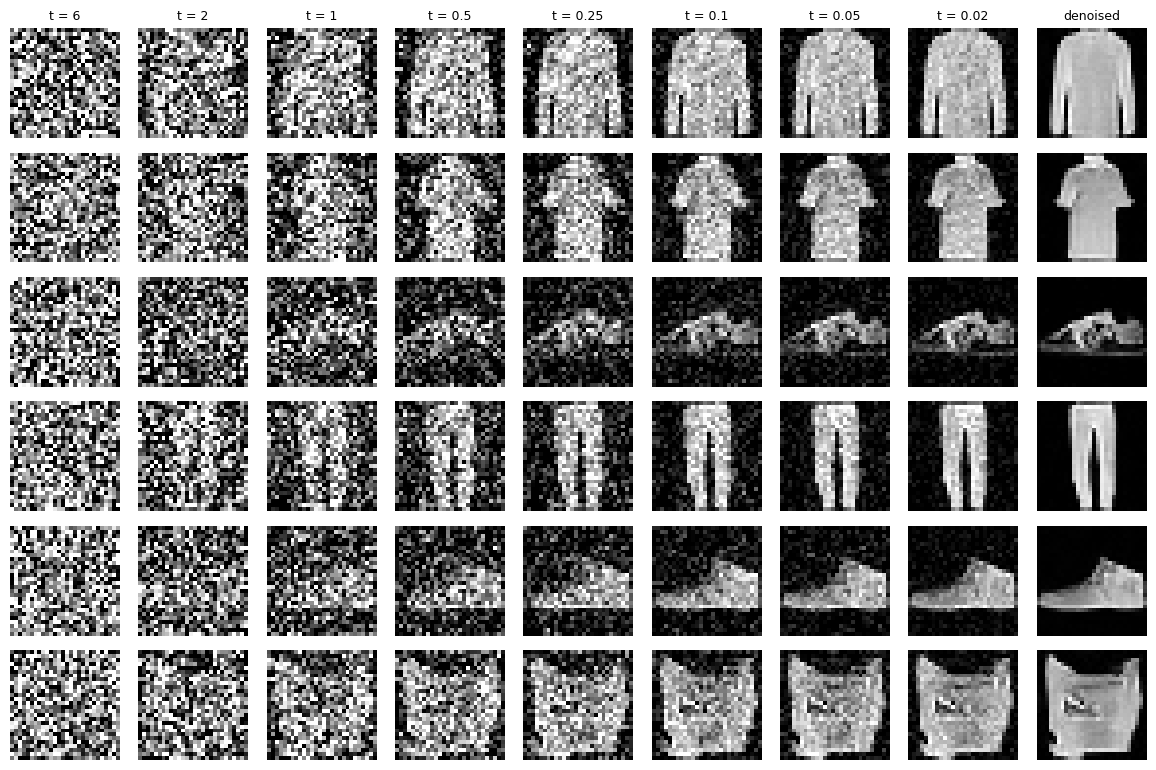

In [11]:
rows = 6
fig, axes = plt.subplots(rows, len(snapshots), figsize=(1.3 * len(snapshots), 1.3 * rows))
for j, (t, x) in enumerate(snapshots):
    for i in range(rows):
        axes[i, j].imshow(x[i, 0].clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
        axes[i, j].axis("off")
    axes[0, j].set_title(f"t = {t:.2g}" if j < len(snapshots) - 1 else "denoised", fontsize=9)
plt.tight_layout()
plt.show()

## Things to try

- **Fewer sampling steps.** Set `N_SAMPLE_STEPS` to 100 or 250. How does sample quality change?
- **The raw network.** Sample with `model` instead of `ema` to see how much the moving average helps.
- **The unweighted loss.** Train on $\|s_\theta + \epsilon/\beta_t\|^2$ directly, as in the slide's original algorithm, with $t_{\min}$ set to $10^{-3}$ and then to $10^{-5}$. What happens to the training loss?
- **A uniform time grid.** Replace `np.geomspace` with `np.linspace` in `sample`. How many steps do you need to get comparable samples?